# Math to Deep Learning with PyTorch: Step-by-Step Notebooks
## Part 1 — Derivatives, Gradients and Backpropagation

A beginner-friendly path from a simple derivative to the core mechanism behind neural-network training.

### 📚 Series Navigation

| Part | Notebook |
|---|---|
| **1** | **Derivatives, Gradients and Backpropagation** |
| **2** | [Activation Functions and the Chain Rule](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-2-activation-func) |
| **3** | [Building a Small Neural Network in PyTorch](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-3-small-nn) |
| **4** | [Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-4-loss-gd-optimiz) |
| **5** | [Training Neural Networks End-to-End in PyTorch](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-5-end2end-nn-train) |


## Goal

After completing this notebook, you should understand:

1. what a derivative means;
2. what partial derivatives and gradients are;
3. how the chain rule works;
4. what `requires_grad`, `grad`, `grad_fn`, and `is_leaf` mean in PyTorch;
5. what `loss.backward()` actually does;
6. how gradients are used to train a model.

> **Backpropagation is an efficient application of the chain rule for computing derivatives of the loss with respect to model parameters.**

## Setup

In [1]:
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

torch.manual_seed(42)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


# 1. The Simplest Derivative

Consider

$$
y=f(x)=x^2
$$

Its derivative is

$$
\frac{dy}{dx}=2x
$$

At $x=3$:

$$
f'(3)=2\cdot3=6
$$

The derivative tells us how sensitive the output is to a small change in the input.

In [2]:
def f(x):
    return x**2

x = 3.0
analytical_derivative = 2 * x

print("f(3) =", f(x))
print("f'(3) =", analytical_derivative)

f(3) = 9.0
f'(3) = 6.0


### 1.1. Numerical Approximation

A derivative can also be approximated numerically:

$$
f'(x)\approx\frac{f(x+h)-f(x)}{h}
$$

for a very small $h$.

In [3]:
h = 1e-4
numerical_derivative = (f(x + h) - f(x)) / h

print("Analytical derivative:", analytical_derivative)
print("Numerical derivative: ", numerical_derivative)

Analytical derivative: 6.0
Numerical derivative:  6.000100000012054


### 1.2. Geometric Meaning — the derivative is the slope of the tangent line.

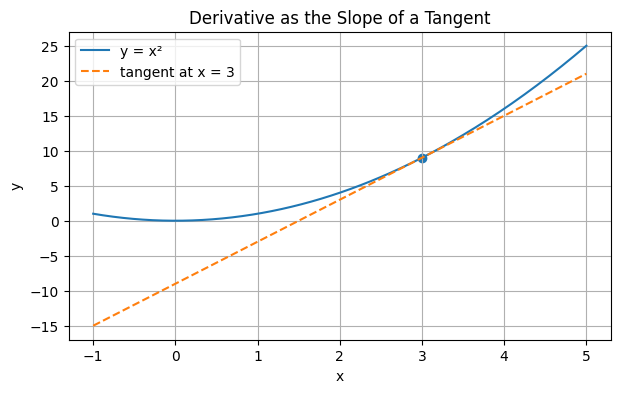

In [4]:
xs = torch.linspace(-1, 5, 200)
ys = xs**2

x0 = 3.0
y0 = x0**2
slope = 2 * x0
tangent = y0 + slope * (xs - x0)

plt.figure(figsize=(7, 4))
plt.plot(xs.numpy(), ys.numpy(), label="y = x²")
plt.plot(xs.numpy(), tangent.numpy(), "--", label="tangent at x = 3")
plt.scatter([x0], [y0])
plt.xlabel("x")
plt.ylabel("y")
plt.title("Derivative as the Slope of a Tangent")
plt.legend()
plt.grid(True)
plt.show()

# 2. The Same Derivative with PyTorch Autograd

PyTorch can build a computation graph and differentiate it automatically.

```python
requires_grad=True
```

means:

> Track operations involving this tensor because gradients will be needed later.

In [5]:
x = torch.tensor(3.0, requires_grad=True)
y = x**2

y.backward()

print("y =", y)
print("dy/dx =", x.grad)

y = tensor(9., grad_fn=<PowBackward0>)
dy/dx = tensor(6.)


The result is

$$
\frac{dy}{dx}=6
$$

and PyTorch stores it in:

```python
x.grad
```

# 3. `grad`, `grad_fn`, and `is_leaf`

### `tensor.grad`
Stores the accumulated gradient for a leaf tensor.

### `tensor.grad_fn`
Shows which tracked operation created the tensor.

### `tensor.is_leaf`
Usually `True` when the tensor was created directly by us rather than by another tracked operation.

In [6]:
x = torch.tensor(3.0, requires_grad=True)
y = x**2
z = y + 5

for name, tensor in [("x", x), ("y", y), ("z", z)]:
    print(
        f"{name}: "
        f"requires_grad={tensor.requires_grad}, "
        f"is_leaf={tensor.is_leaf}, "
        f"grad_fn={tensor.grad_fn}"
    )

x: requires_grad=True, is_leaf=True, grad_fn=None
y: requires_grad=True, is_leaf=False, grad_fn=<PowBackward0 object at 0x789d34eaba90>
z: requires_grad=True, is_leaf=False, grad_fn=<AddBackward0 object at 0x789d34eaba90>


Typical behavior:

| Tensor | Created by | `is_leaf` | `grad_fn` |
|---|---|---:|---|
| `x` | us directly | `True` | `None` |
| `y=x²` | an operation | `False` | present |
| `z=y+5` | an operation | `False` | present |

By default, PyTorch retains `.grad` for leaf tensors, not for intermediate tensors.

In [7]:
x = torch.tensor(3.0, requires_grad=True)
y = x**2
y.retain_grad()
z = y + 5

z.backward()

print("x.grad =", x.grad)
print("y.grad =", y.grad)

x.grad = tensor(6.)
y.grad = tensor(1.)


# 4. From a Derivative to a Gradient

For a function of several variables,

$$
f(x,y)=x^2+3y^2
$$

the partial derivatives are

$$
\frac{\partial f}{\partial x}=2x
$$

and

$$
\frac{\partial f}{\partial y}=6y
$$

Together they form the gradient:

$$
\nabla f=
\begin{bmatrix}
2x\\
6y
\end{bmatrix}
$$

In [8]:
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

value = x**2 + 3*y**2
value.backward()

print("f =", value.item())
print("df/dx =", x.grad.item())
print("df/dy =", y.grad.item())

f = 31.0
df/dx = 4.0
df/dy = 18.0


For model parameters

$$
\theta=[w_1,w_2,b,\dots]
$$

the loss gradient is

$$
\nabla_\theta L=
\left[
\frac{\partial L}{\partial w_1},
\frac{\partial L}{\partial w_2},
\frac{\partial L}{\partial b},
\dots
\right]
$$

It tells us how the loss changes when each parameter changes slightly.

# 5. The Chain Rule — the Foundation of Backpropagation

Consider

$$
x\rightarrow y=x^2\rightarrow z=3y\rightarrow L=z+1
$$

Then

$$
\frac{dL}{dx}
=
\frac{dL}{dz}
\cdot
\frac{dz}{dy}
\cdot
\frac{dy}{dx}
$$

Since

$$
\frac{dL}{dz}=1,\qquad
\frac{dz}{dy}=3,\qquad
\frac{dy}{dx}=2x
$$

we get

$$
\frac{dL}{dx}=6x
$$

and at $x=2$:

$$
\frac{dL}{dx}=12
$$

In [9]:
x_value = 2.0

dy_dx = 2 * x_value
dz_dy = 3.0
dL_dz = 1.0

manual_gradient = dL_dz * dz_dy * dy_dx
print("Manual dL/dx =", manual_gradient)

Manual dL/dx = 12.0


In [10]:
x = torch.tensor(2.0, requires_grad=True)

y = x**2
z = 3*y
loss = z + 1

loss.backward()

print("PyTorch dL/dx =", x.grad.item())

PyTorch dL/dx = 12.0


This is the essence of backpropagation:

**Forward**

$$
x\rightarrow y\rightarrow z\rightarrow L
$$

**Backward**

$$
L\rightarrow z\rightarrow y\rightarrow x
$$

PyTorch moves backward through the graph and applies the chain rule.

# 6. A Very Simple Neuron

Let

$$
\hat y=wx+b
$$

Take:

- $x=2$
- target $y=5$
- $w=1$
- $b=0$

Then

$$
\hat y=2
$$

Using squared error:

$$
L=(\hat y-y)^2=(2-5)^2=9
$$

### 6.1. Diagram of One Neuron

The computation is:

$$
x \xrightarrow{\times w} wx \xrightarrow{+b} \hat y \xrightarrow{\text{compare with }y} L
$$

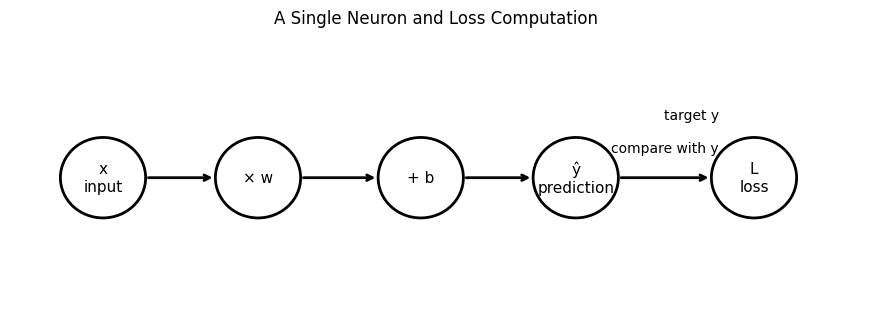

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.set_xlim(0, 11)
ax.set_ylim(0, 4)
ax.axis("off")

nodes = [
    ((1.2, 2.0), "x\ninput"),
    ((3.2, 2.0), "× w"),
    ((5.3, 2.0), "+ b"),
    ((7.3, 2.0), "ŷ\nprediction"),
    ((9.6, 2.0), "L\nloss"),
]

for (cx, cy), label in nodes:
    circle = Circle((cx, cy), 0.55, fill=False, linewidth=2)
    ax.add_patch(circle)
    ax.text(cx, cy, label, ha="center", va="center", fontsize=11)

def arrow(x1, y1, x2, y2, label=None):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=2),
    )
    if label:
        ax.text((x1+x2)/2, 2.35, label, ha="center", fontsize=10)

arrow(1.75, 2, 2.65, 2)
arrow(3.75, 2, 4.75, 2)
arrow(5.85, 2, 6.75, 2)
arrow(7.85, 2, 9.05, 2, "compare with y")

ax.text(8.8, 2.8, "target y", ha="center", fontsize=10)
ax.set_title("A Single Neuron and Loss Computation")
plt.show()

In [12]:
x = 2.0
target = 5.0
w = 1.0
b = 0.0

prediction = w*x + b
loss = (prediction - target)**2

print("prediction =", prediction)
print("loss =", loss)

prediction = 2.0
loss = 9.0


# 7. Backpropagation by Hand

We have

$$
L=(\hat y-y)^2
$$

and

$$
\hat y=wx+b
$$

First:

$$
\frac{\partial L}{\partial \hat y}=2(\hat y-y)
$$

For our example:

$$
2(2-5)=-6
$$

Then:

$$
\frac{\partial \hat y}{\partial w}=x=2
$$

Therefore:

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial \hat y}
\frac{\partial \hat y}{\partial w}
=
-6\cdot2=-12
$$

For the bias:

$$
\frac{\partial L}{\partial b}=-6
$$

In [13]:
dL_dprediction = 2 * (prediction - target)
dprediction_dw = x
dprediction_db = 1

dL_dw = dL_dprediction * dprediction_dw
dL_db = dL_dprediction * dprediction_db

print("dL/dw =", dL_dw)
print("dL/db =", dL_db)

dL/dw = -12.0
dL/db = -6.0


# 8. The Same Backpropagation with PyTorch

In [14]:
x = torch.tensor(2.0)
target = torch.tensor(5.0)

w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

prediction = w*x + b
loss = (prediction - target)**2

loss.backward()

print("prediction =", prediction.item())
print("loss =", loss.item())
print("w.grad =", w.grad.item())
print("b.grad =", b.grad.item())

prediction = 2.0
loss = 9.0
w.grad = -12.0
b.grad = -6.0


PyTorch returns the same derivatives:

$$
\frac{\partial L}{\partial w}=-12
$$

$$
\frac{\partial L}{\partial b}=-6
$$

# 9. Gradient Descent

To reduce the loss, we update parameters in the opposite direction of the gradient:

$$
w_{\text{new}}
=
w_{\text{old}}
-
\eta
\frac{\partial L}{\partial w}
$$

where $\eta$ is the learning rate.

In [15]:
learning_rate = 0.1
w_old = 1.0
gradient = -12.0

w_new = w_old - learning_rate * gradient

print("old w =", w_old)
print("new w =", w_new)

old w = 1.0
new w = 2.2


# 10. One Complete Training Step

In [16]:
x = torch.tensor(2.0)
target = torch.tensor(5.0)

w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

learning_rate = 0.1

# Forward
prediction = w*x + b
loss = (prediction - target)**2

print("BEFORE UPDATE")
print("prediction:", prediction.item())
print("loss:", loss.item())

# Backward
loss.backward()

print("grad w:", w.grad.item())
print("grad b:", b.grad.item())

# Update parameters
with torch.no_grad():
    w -= learning_rate * w.grad
    b -= learning_rate * b.grad

new_prediction = w*x + b
new_loss = (new_prediction - target)**2

print("\nAFTER UPDATE")
print("w:", w.item())
print("b:", b.item())
print("new prediction:", new_prediction.item())
print("new loss:", new_loss.item())

BEFORE UPDATE
prediction: 2.0
loss: 9.0
grad w: -12.0
grad b: -6.0

AFTER UPDATE
w: 2.200000047683716
b: 0.6000000238418579
new prediction: 5.0
new loss: 0.0


The loss should become smaller.

`torch.no_grad()` is important because the parameter update itself should not become part of the next autograd graph.

# 11. Why Do We Clear Gradients?

PyTorch **accumulates** gradients.

If we do not clear them, new gradients are added to old ones.

In [17]:
w = torch.tensor(2.0, requires_grad=True)

loss1 = w**2
loss1.backward()
print("After first backward:", w.grad.item())

loss2 = w**2
loss2.backward()
print("After second backward:", w.grad.item())

w.grad.zero_()
print("After zeroing:", w.grad.item())

After first backward: 4.0
After second backward: 8.0
After zeroing: 0.0


With an optimizer, the standard pattern is:

```python
optimizer.zero_grad()
prediction = model(X)
loss = ...
loss.backward()
optimizer.step()
```

# 12. Tiny Gradient Descent Without `torch.optim`

We now train

$$
\hat y=wx+b
$$

on points generated by

$$
y=2x+1
$$

The model should learn approximately

$$
w\approx2,\qquad b\approx1
$$

In [18]:
X = torch.tensor([0., 1., 2., 3., 4.])
Y = 2*X + 1

w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

learning_rate = 0.05
loss_history = []

for epoch in range(100):
    predictions = w*X + b
    loss = ((predictions - Y)**2).mean()

    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    w.grad.zero_()
    b.grad.zero_()

    loss_history.append(loss.item())

print("Learned w =", w.item())
print("Learned b =", b.item())
print("Final loss =", loss_history[-1])

Learned w = 2.004504680633545
Learned b = 0.9871583580970764
Final loss = 5.872276960872114e-05


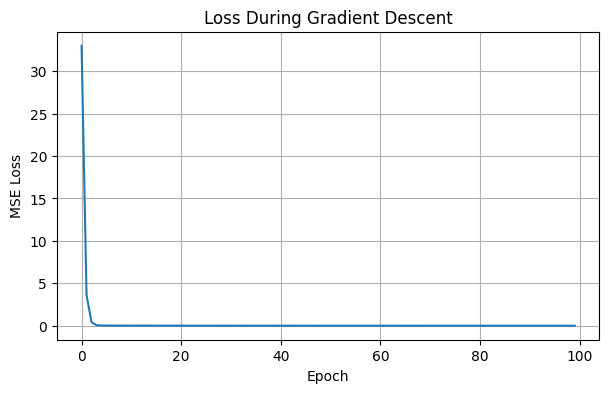

In [19]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Loss During Gradient Descent")
plt.grid(True)
plt.show()

# 13. The Same Idea with `nn.Module` and `torch.optim`

In [20]:
from torch import nn

X = torch.tensor([[0.], [1.], [2.], [3.], [4.]])
Y = 2*X + 1

model = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

for epoch in range(200):
    optimizer.zero_grad()

    predictions = model(X)
    loss = criterion(predictions, Y)

    loss.backward()
    optimizer.step()

print("Learned weight =", model.weight.item())
print("Learned bias   =", model.bias.item())
print("Final loss     =", loss.item())

Learned weight = 1.9998079538345337
Learned bias   = 1.0005476474761963
Final loss     = 1.0681075224283632e-07


### 13.1. A Small Neural Network

Now imagine that instead of one neuron, we have several connected neurons.

During the **forward pass**, values move from inputs to outputs.

During **backpropagation**, gradient information moves from the loss backward through all layers.

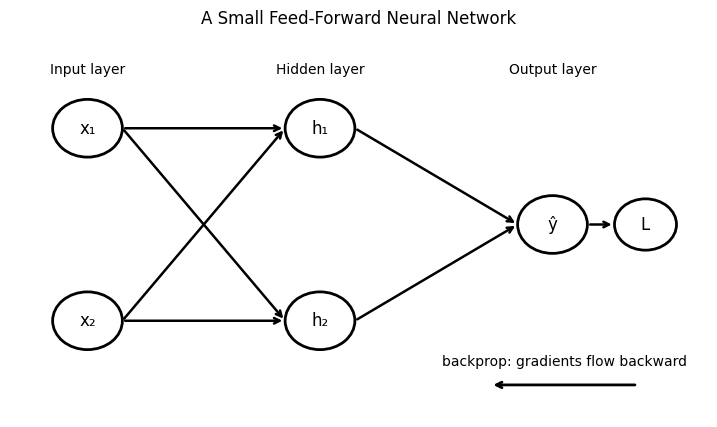

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xlim(0, 9)
ax.set_ylim(0, 6)
ax.axis("off")

inputs = [(1.0, 4.5, "x₁"), (1.0, 1.5, "x₂")]
hidden = [(4.0, 4.5, "h₁"), (4.0, 1.5, "h₂")]
output = [(7.0, 3.0, "ŷ")]

for x, y, label in inputs + hidden + output:
    circle = Circle((x, y), 0.45, fill=False, linewidth=2)
    ax.add_patch(circle)
    ax.text(x, y, label, ha="center", va="center", fontsize=12)

for ix, iy, _ in inputs:
    for hx, hy, _ in hidden:
        ax.annotate(
            "",
            xy=(hx - 0.45, hy),
            xytext=(ix + 0.45, iy),
            arrowprops=dict(arrowstyle="->", lw=1.8),
        )

for hx, hy, _ in hidden:
    ax.annotate(
        "",
        xy=(6.55, 3.0),
        xytext=(hx + 0.45, hy),
        arrowprops=dict(arrowstyle="->", lw=1.8),
    )

loss_circle = Circle((8.2, 3.0), 0.4, fill=False, linewidth=2)
ax.add_patch(loss_circle)
ax.text(8.2, 3.0, "L", ha="center", va="center", fontsize=12)
ax.annotate("", xy=(7.8, 3.0), xytext=(7.45, 3.0),
            arrowprops=dict(arrowstyle="->", lw=1.8))

ax.text(1.0, 5.35, "Input layer", ha="center")
ax.text(4.0, 5.35, "Hidden layer", ha="center")
ax.text(7.0, 5.35, "Output layer", ha="center")

ax.annotate("", xy=(6.2, 0.5), xytext=(8.1, 0.5),
            arrowprops=dict(arrowstyle="->", lw=2))
ax.text(7.15, 0.8, "backprop: gradients flow backward",
        ha="center", fontsize=10)

ax.set_title("A Small Feed-Forward Neural Network")
plt.show()

# 14. What Does `loss.backward()` Actually Do?

In simplified form, PyTorch:

1. starts from `loss`;
2. checks which operation created it;
3. computes the local derivative;
4. moves backward through `grad_fn`;
5. applies the chain rule;
6. accumulates the result in `.grad` of leaf parameters.

```text
x ──┐
    ├──> model ──> prediction ──> loss
w ──┤                         │
b ──┘                         ▼
                           backward()
                              │
                    ┌─────────┴─────────┐
                    ▼                   ▼
                  w.grad              b.grad
```

# 15. Gradient as a Vector

For one neuron with two inputs:

$$
z=w_1x_1+w_2x_2+b
$$

the gradient with respect to the weights is

$$
\left[
\frac{\partial L}{\partial w_1},
\frac{\partial L}{\partial w_2}
\right]
$$

In [22]:
x = torch.tensor([2.0, 3.0])
target = torch.tensor(4.0)

w = torch.tensor([0.5, -1.0], requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

prediction = (w * x).sum() + b
loss = (prediction - target)**2

loss.backward()

print("prediction =", prediction.item())
print("loss =", loss.item())
print("w.grad =", w.grad)
print("b.grad =", b.grad)

prediction = -1.0
loss = 25.0
w.grad = tensor([-20., -30.])
b.grad = tensor(-10.)


# Checks

## 16. Small Exercises

### Exercise 1

For

$$
y=x^3
$$

find the derivative manually and with PyTorch at $x=2$.

Expected formula:

$$
\frac{dy}{dx}=3x^2
$$

### Exercise 2

For

$$
f(x,y)=x^2+xy+y^2
$$

at $x=2,\ y=3$, compute

$$
\frac{\partial f}{\partial x}
\qquad\text{and}\qquad
\frac{\partial f}{\partial y}
$$

### Exercise 3

Try several learning rates:

```python
0.001
0.01
0.05
0.5
```

Observe when learning is slow, stable, or unstable.

In [23]:
# Exercise 1
x = torch.tensor(2.0, requires_grad=True)

# y = x**3
# y.backward()
# print(x.grad)

# 17. Quick Cheat Sheet

| Concept | Meaning |
|---|---|
| derivative | rate of change |
| partial derivative | derivative with respect to one variable |
| gradient | vector of partial derivatives |
| `requires_grad=True` | tells PyTorch to track operations |
| `grad_fn` | operation that created a tensor |
| `is_leaf` | whether the tensor is a starting node |
| `.grad` | accumulated gradient |
| `.backward()` | starts backward differentiation |
| chain rule | differentiates composite functions |
| backpropagation | chain rule applied efficiently through the graph |
| gradient descent | updates parameters to reduce loss |
| `zero_grad()` | clears old gradients |
| `optimizer.step()` | updates parameters |

# Next Steps

The core pattern is:

$$
\boxed{
\text{Forward}
\rightarrow
\text{Loss}
\rightarrow
\text{Backward}
\rightarrow
\text{Gradients}
\rightarrow
\text{Update}
}
$$

## ➡️ Continue the Series

### Part 2
[**Activation Functions and the Chain Rule**](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-2-activation-func)

Topics:

- Sigmoid
- Tanh
- ReLU
- derivatives of activation functions
- why nonlinear activations are necessary
- gradients through multiple operations

### Full Series

1. **Part 1 — Derivatives, Gradients and Backpropagation** ← you are here  
2. [Part 2 — Activation Functions and the Chain Rule](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-2-activation-func)  
3. [Part 3 — Building a Small Neural Network in PyTorch](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-3-small-nn)  
4. [Part 4 — Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-4-loss-gd-optimiz)  
5. [Part 5 — Training Neural Networks End-to-End in PyTorch](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-5-end2end-nn-train)

## Found this notebook useful? An upvote 👍 would be greatly appreciated!